# Turbofan engine remaining-useful-life (RUL) prediction: data exploration and baselines

Naji El Kharsa, project proposal code. Data: NASA C-MAPSS (Saxena et al., 2008).
Run on Google Colab (CPU is enough): **Runtime → Run all**. The notebook downloads the data, explores it, and runs
the baselines with an engine-wise (grouped) cross-validation on the training set plus one evaluation on the official
FD001 test set. Figures are saved as PNG files and all numbers are collected in `results.json`.

In [1]:
import io, os, json, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

DATA_DIR = "CMAPSSData"
SOURCES = [
    "https://data.nasa.gov/docs/legacy/CMAPSSData.zip",   # official NASA PCoE copy
]
HF_MIRROR = "https://huggingface.co/datasets/SoyVitou/NASA-C-MAPSS-Turbofan-Engine/resolve/main/data/{}"
FILES = [f"{kind}_FD00{i}.txt" for i in range(1, 5) for kind in ("train", "test", "RUL")]

def download_cmapss():
    os.makedirs(DATA_DIR, exist_ok=True)
    if all(os.path.exists(os.path.join(DATA_DIR, f)) for f in FILES):
        return "cached"
    for url in SOURCES:
        try:
            raw = urllib.request.urlopen(url, timeout=60).read()
            with zipfile.ZipFile(io.BytesIO(raw)) as z:
                for name in z.namelist():
                    base = os.path.basename(name)
                    if base in FILES:
                        with open(os.path.join(DATA_DIR, base), "wb") as f:
                            f.write(z.read(name))
            if all(os.path.exists(os.path.join(DATA_DIR, f)) for f in FILES):
                return url
        except Exception as e:
            print("source failed:", url, "->", type(e).__name__, e)
    for f in FILES:                                         # fallback: file-by-file mirror
        with open(os.path.join(DATA_DIR, f), "wb") as out:
            out.write(urllib.request.urlopen(HF_MIRROR.format(f), timeout=60).read())
    return "huggingface mirror"

print("data source:", download_cmapss())

data source: https://data.nasa.gov/docs/legacy/CMAPSSData.zip


## Load and label

Each file has 26 space-separated columns: engine id, cycle, 3 operating settings and 21 sensors. Training engines run
until failure, so the remaining useful life of a row is `last cycle - current cycle`. Following common practice
(Heimes, 2008; Li et al., 2018) the training target is capped at **125 cycles** (piecewise-linear RUL), because early in
life the engine is healthy and its exact RUL cannot be read from the sensors.

In [2]:
COLS = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
SENSOR_NAMES = {"s2": "T24 LPC outlet temp (°R)", "s3": "T30 HPC outlet temp (°R)", "s4": "T50 LPT outlet temp (°R)",
                "s7": "P30 HPC outlet pressure (psia)", "s11": "Ps30 HPC static pressure (psia)",
                "s12": "phi fuel flow / Ps30 (pps/psi)", "s15": "BPR bypass ratio (-)", "s21": "W32 LPT coolant bleed (lbm/s)"}
RUL_CAP = 125

def load(subset="FD001"):
    rd = lambda f: pd.read_csv(os.path.join(DATA_DIR, f), sep=r"\s+", header=None).iloc[:, :26]
    train, test = rd(f"train_{subset}.txt"), rd(f"test_{subset}.txt")
    train.columns = COLS; test.columns = COLS
    rul_test = rd(f"RUL_{subset}.txt").iloc[:, 0].to_numpy()
    life = train.groupby("unit")["cycle"].transform("max")
    train["RUL"] = life - train["cycle"]
    train["RUL_capped"] = train["RUL"].clip(upper=RUL_CAP)
    return train, test, rul_test

train, test, rul_test = load("FD001")
print("train rows:", len(train), " engines:", train.unit.nunique(),
      "| test rows:", len(test), " engines:", test.unit.nunique(), "| missing values:", int(train.isna().sum().sum()))

train rows: 20631  engines: 100 | test rows: 13096  engines: 100 | missing values: 0


## Explore

{
 "train_rows": 20631,
 "train_engines": 100,
 "test_rows": 13096,
 "test_engines": 100,
 "lifetime_min": 128,
 "lifetime_mean": 206.31,
 "lifetime_median": 199.0,
 "lifetime_max": 362,
 "lifetime_std": 46.3427492067573,
 "test_observed_min": 31,
 "test_observed_max": 303,
 "test_true_rul_min": 7,
 "test_true_rul_mean": 75.52,
 "test_true_rul_max": 145,
 "share_rows_at_cap": 0.3941156512044981,
 "constant_columns": [
  "op1",
  "op2",
  "op3",
  "s1",
  "s5",
  "s6",
  "s10",
  "s16",
  "s18",
  "s19"
 ],
 "informative_sensors": [
  "s2",
  "s3",
  "s4",
  "s7",
  "s8",
  "s9",
  "s11",
  "s12",
  "s13",
  "s14",
  "s15",
  "s17",
  "s20",
  "s21"
 ],
 "top_corr": {
  "s11": 0.775229821871158,
  "s4": 0.7571567446044734,
  "s12": 0.7488698691357298,
  "s7": 0.7330210310750626,
  "s15": 0.7208584828528034,
  "s21": 0.7073341478068336
 },
 "missing_values": 0,
 "duplicate_rows": 0,
 "fd002_rows": 53759,
 "fd002_engines": 260,
 "fd002_operating_conditions": 6
}


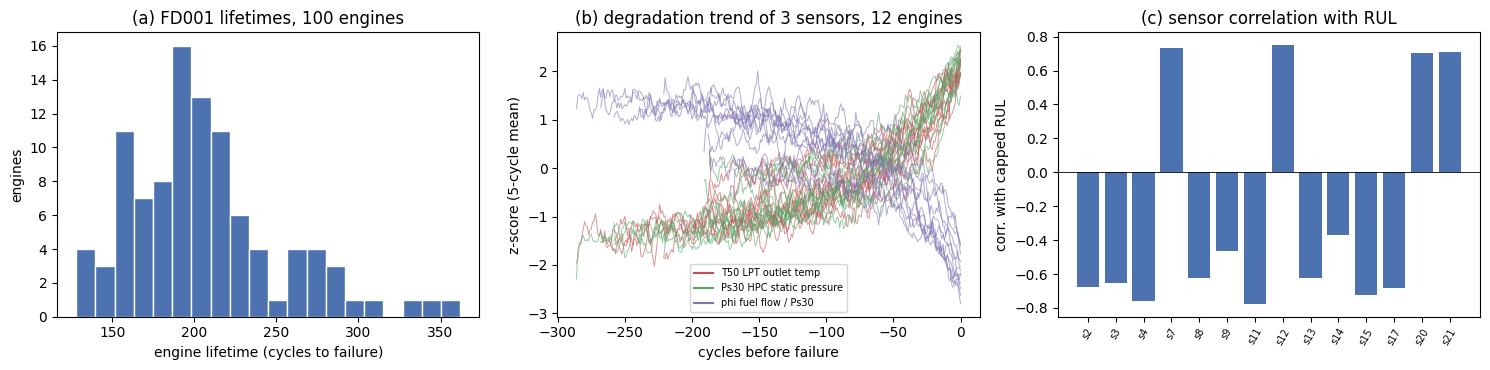

In [3]:
lifetimes = train.groupby("unit")["cycle"].max()
test_len = test.groupby("unit")["cycle"].max()
stds = train[COLS[2:]].std()
constant = [c for c in COLS[2:] if stds[c] < 0.02]          # flat columns (std below 0.02 in raw units)
corr = train[COLS[2:] + ["RUL_capped"]].corr()["RUL_capped"].drop("RUL_capped")
SENSORS = [c for c in COLS[5:] if c not in constant and abs(corr[c]) > 0.1]
if len(SENSORS) < 5:   # safety net: the 14 sensors used in most C-MAPSS papers
    SENSORS = ["s2", "s3", "s4", "s7", "s8", "s9", "s11", "s12", "s13", "s14", "s15", "s17", "s20", "s21"]

fd2_train, _, _ = load("FD002")
n_conditions = fd2_train[["op1", "op2", "op3"]].round(0).drop_duplicates().shape[0]

stats = {
    "train_rows": int(len(train)), "train_engines": int(train.unit.nunique()),
    "test_rows": int(len(test)), "test_engines": int(test.unit.nunique()),
    "lifetime_min": int(lifetimes.min()), "lifetime_mean": float(lifetimes.mean()), "lifetime_median": float(lifetimes.median()),
    "lifetime_max": int(lifetimes.max()), "lifetime_std": float(lifetimes.std()),
    "test_observed_min": int(test_len.min()), "test_observed_max": int(test_len.max()),
    "test_true_rul_min": int(rul_test.min()), "test_true_rul_mean": float(rul_test.mean()), "test_true_rul_max": int(rul_test.max()),
    "share_rows_at_cap": float((train.RUL >= RUL_CAP).mean()),
    "constant_columns": constant, "informative_sensors": SENSORS,
    "top_corr": {k: float(v) for k, v in corr.reindex(SENSORS).abs().sort_values(ascending=False).head(6).items()},
    "missing_values": int(train.isna().sum().sum()), "duplicate_rows": int(train.duplicated(["unit", "cycle"]).sum()),
    "fd002_rows": int(len(fd2_train)), "fd002_engines": int(fd2_train.unit.nunique()), "fd002_operating_conditions": int(n_conditions),
}
print(json.dumps(stats, indent=1))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(lifetimes, bins=20, color="#4c72b0", edgecolor="white")
axes[0].set_xlabel("engine lifetime (cycles to failure)"); axes[0].set_ylabel("engines")
axes[0].set_title(f"(a) FD001 lifetimes, {len(lifetimes)} engines")
for s, col in [("s4", "#c44e52"), ("s11", "#55a868"), ("s12", "#8172b2")]:
    z = (train[s] - train[s].mean()) / train[s].std()
    for u in train.unit.unique()[:12]:
        m = train.unit == u
        axes[1].plot(-train.loc[m, "RUL"], z[m].rolling(5, min_periods=1).mean(), color=col, lw=0.7, alpha=0.6)
    axes[1].plot([], [], color=col, label=SENSOR_NAMES[s].split(" (")[0])
axes[1].set_xlabel("cycles before failure"); axes[1].set_ylabel("z-score (5-cycle mean)")
axes[1].set_title("(b) degradation trend of 3 sensors, 12 engines"); axes[1].legend(fontsize=7)
c = corr.reindex([s for s in COLS[5:] if s not in constant])
axes[2].bar(c.index, c.values, color=["#4c72b0" if s in SENSORS else "#bbbbbb" for s in c.index])
axes[2].axhline(0, color="k", lw=0.6); axes[2].tick_params(axis="x", rotation=60, labelsize=7)
axes[2].set_ylabel("corr. with capped RUL"); axes[2].set_title("(c) sensor correlation with RUL")
plt.tight_layout(); plt.savefig("fig_eda.png", dpi=200); plt.show()

## Features and baselines

* **M0, constant:** predicts the mean (capped) training RUL for every input. It shows how far you get with no sensor
  information at all.
* **M1, ridge regression:** a linear model on the standardised current values of the informative sensors.
* **M2, gradient boosting on window features:** for each cycle, the current value plus the mean, standard deviation and
  slope of every informative sensor over the last 30 cycles (Histogram Gradient Boosting, scikit-learn).

Validation is a **5-fold GroupKFold by engine**, so no engine appears in both training and validation and no time steps
leak. The validation metrics are computed on all rows of the held-out engines (capped target). The official FD001 test
set is used once, at the last observed cycle of each test engine, against the true RUL given by NASA.

In [4]:
W = 30
def window_features(df):
    df = df.sort_values(["unit", "cycle"]).copy()
    g = df.groupby("unit")
    feats = {}
    for s in SENSORS:
        feats[f"{s}_now"] = df[s]
        feats[f"{s}_mean"] = g[s].transform(lambda x: x.rolling(W, min_periods=1).mean())
        feats[f"{s}_std"] = g[s].transform(lambda x: x.rolling(W, min_periods=2).std()).fillna(0.0)
        cov = g[s].transform(lambda x: x.rolling(W, min_periods=2).cov(pd.Series(np.arange(len(x)), index=x.index)))
        var = g["cycle"].transform(lambda x: x.rolling(W, min_periods=2).var())
        feats[f"{s}_slope"] = (cov / var).fillna(0.0)
    return df, pd.DataFrame(feats, index=df.index)

def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return {"RMSE": float(np.sqrt(np.mean((y_pred - y_true) ** 2))), "MAE": float(np.mean(np.abs(y_pred - y_true))),
            "late_share": float(np.mean(y_pred > y_true))}

class Constant:
    def fit(self, X, y): self.c = float(np.mean(y)); return self
    def predict(self, X): return np.full(len(X), self.c)

train_s, Xw_train = window_features(train)
test_s, Xw_test = window_features(test)
y = train_s["RUL_capped"].to_numpy()
groups = train_s["unit"].to_numpy()
last_idx = test_s.groupby("unit").tail(1).index
y_test = rul_test                                   # true RUL of each test engine (unit order 1..100)

MODELS = {
    "M0 constant (mean RUL)": (lambda: Constant(), lambda d, w: d[SENSORS]),
    "M1 ridge, current sensors": (lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)), lambda d, w: d[SENSORS]),
    "M2 gradient boosting, 30-cycle window": (lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05,
                                                                                   random_state=0), lambda d, w: w),
}

results = {}
gkf = GroupKFold(n_splits=5)
for name, (make, feats) in MODELS.items():
    X_all = feats(train_s, Xw_train)
    tr_m, va_m = [], []
    for tr, va in gkf.split(X_all, y, groups):
        m = make().fit(X_all.iloc[tr], y[tr])
        tr_m.append(metrics(y[tr], m.predict(X_all.iloc[tr])))
        va_m.append(metrics(y[va], m.predict(X_all.iloc[va])))
    final = make().fit(X_all, y)
    X_te = feats(test_s, Xw_test).loc[last_idx]
    pred_te = np.clip(final.predict(X_te), 0, None)
    results[name] = {
        "train_RMSE": float(np.mean([r["RMSE"] for r in tr_m])),
        "val_RMSE": float(np.mean([r["RMSE"] for r in va_m])), "val_RMSE_std": float(np.std([r["RMSE"] for r in va_m])),
        "val_MAE": float(np.mean([r["MAE"] for r in va_m])),
        "test_RMSE": metrics(y_test, pred_te)["RMSE"], "test_MAE": metrics(y_test, pred_te)["MAE"],
        "test_score": nasa_score(y_test, pred_te), "test_late_share": metrics(y_test, pred_te)["late_share"],
        "test_pred": pred_te.round(2).tolist(),
    }
    r = results[name]
    print(f"{name:42s} train RMSE {r['train_RMSE']:6.2f} | val RMSE {r['val_RMSE']:6.2f} ± {r['val_RMSE_std']:.2f} "
          f"| test RMSE {r['test_RMSE']:6.2f}  MAE {r['test_MAE']:6.2f}  NASA score {r['test_score']:9.1f}  late {r['test_late_share']:.0%}")

M0 constant (mean RUL)                     train RMSE  41.67 | val RMSE  41.67 ± 0.00 | test RMSE  43.07  MAE  35.90  NASA score   33629.2  late 50%
M1 ridge, current sensors                  train RMSE  21.48 | val RMSE  21.57 ± 1.08 | test RMSE  21.90  MAE  17.61  NASA score    1313.9  late 59%
M2 gradient boosting, 30-cycle window      train RMSE   4.63 | val RMSE  12.96 ± 0.76 | test RMSE  14.11  MAE  10.76  NASA score     277.5  late 58%


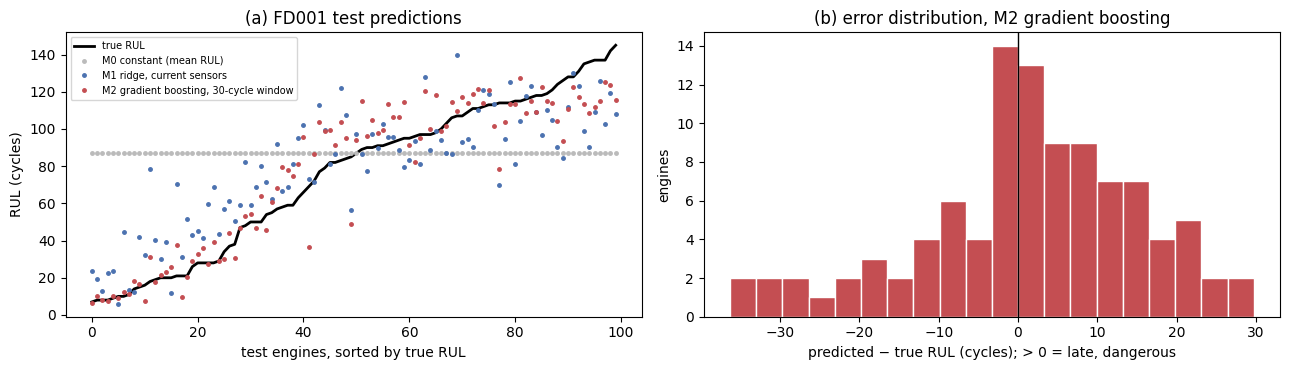

{
 "stats": {
  "train_rows": 20631,
  "train_engines": 100,
  "test_rows": 13096,
  "test_engines": 100,
  "lifetime_min": 128,
  "lifetime_mean": 206.31,
  "lifetime_median": 199.0,
  "lifetime_max": 362,
  "lifetime_std": 46.3427492067573,
  "test_observed_min": 31,
  "test_observed_max": 303,
  "test_true_rul_min": 7,
  "test_true_rul_mean": 75.52,
  "test_true_rul_max": 145,
  "share_rows_at_cap": 0.3941156512044981,
  "constant_columns": [
   "op1",
   "op2",
   "op3",
   "s1",
   "s5",
   "s6",
   "s10",
   "s16",
   "s18",
   "s19"
  ],
  "informative_sensors": [
   "s2",
   "s3",
   "s4",
   "s7",
   "s8",
   "s9",
   "s11",
   "s12",
   "s13",
   "s14",
   "s15",
   "s17",
   "s20",
   "s21"
  ],
  "top_corr": {
   "s11": 0.775229821871158,
   "s4": 0.7571567446044734,
   "s12": 0.7488698691357298,
   "s7": 0.7330210310750626,
   "s15": 0.7208584828528034,
   "s21": 0.7073341478068336
  },
  "missing_values": 0,
  "duplicate_rows": 0,
  "fd002_rows": 53759,
  "fd002_engines":

In [5]:
best = min(results, key=lambda k: results[k]["test_RMSE"])
order = np.argsort(y_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(np.arange(len(y_test)), y_test[order], "k-", lw=2, label="true RUL")
for name, col in zip(results, ["#bbbbbb", "#4c72b0", "#c44e52"]):
    axes[0].plot(np.arange(len(y_test)), np.array(results[name]["test_pred"])[order], ".", ms=5, color=col, label=name)
axes[0].set_xlabel("test engines, sorted by true RUL"); axes[0].set_ylabel("RUL (cycles)")
axes[0].set_title("(a) FD001 test predictions"); axes[0].legend(fontsize=7)
err = np.array(results[best]["test_pred"]) - y_test
axes[1].hist(err, bins=20, color="#c44e52", edgecolor="white")
axes[1].axvline(0, color="k", lw=1)
axes[1].set_xlabel("predicted − true RUL (cycles); > 0 = late, dangerous")
axes[1].set_ylabel("engines"); axes[1].set_title(f"(b) error distribution, {best.split(',')[0]}")
plt.tight_layout(); plt.savefig("fig_baseline.png", dpi=200); plt.show()

json.dump({"stats": stats, "results": results, "rul_cap": RUL_CAP, "window": W}, open("results.json", "w"), indent=1)
print(json.dumps({"stats": stats, "results": {k: {kk: vv for kk, vv in v.items() if kk != "test_pred"} for k, v in results.items()}}, indent=1))